<a href="https://colab.research.google.com/github/seonilj/data-science-python-neuroscience/blob/main/assignments/DSPY_task3_reverse_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Data Loading & Audit

In [4]:
# 1. Load data
base = '/content/drive/MyDrive/Colab Notebooks'
data_path = base + '/_data/spike_data.npz'
utils_path = base + '/_utils'
out_dir = base + '/_data'  # results saved next to the original data
os.makedirs(utils_path, exist_ok=True)
if utils_path not in sys.path:
    sys.path.append(utils_path)

data = np.load(data_path)
t, raw_data = data['t'], data['raw_data']
print("Arrays:", data.files)
print("Shapes:", t.shape, raw_data.shape, "| dtypes:", t.dtype, raw_data.dtype)

Arrays: ['t', 'raw_data']
Shapes: (10000,) (10000,) | dtypes: float64 float64


Samples: 10000, duration: 10.00 s, fs: 1000.0 Hz
Mean: 0.077, Std: 0.734, Min: -1.691, Max: 6.202


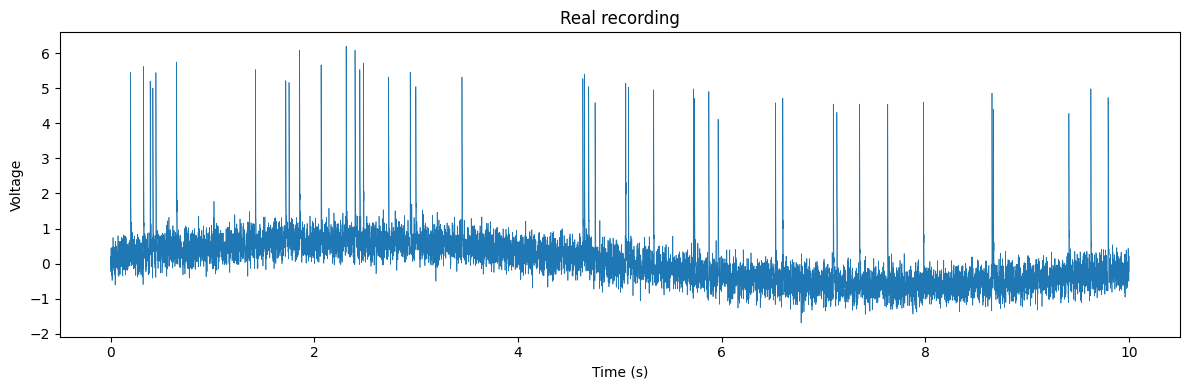

In [5]:
# 2. Basic properties and a first look
dt = np.median(np.diff(t))             # sampling interval
fs = 1 / dt                            # sampling frequency (Hz)
duration_s = len(t) / fs
mean, std = np.mean(raw_data), np.std(raw_data)

print(f"Samples: {len(t)}, duration: {duration_s:.2f} s, fs: {fs:.1f} Hz")
print(f"Mean: {mean:.3f}, Std: {std:.3f}, Min: {raw_data.min():.3f}, Max: {raw_data.max():.3f}")

plt.figure(figsize=(12, 4))
plt.plot(t, raw_data, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Voltage")
plt.title("Real recording")
plt.tight_layout()
plt.show()

# 2. Detector

In [6]:
# 3. Spike detector: index of the first sample above threshold (rising edge)
def detect_spikes(signal, threshold):
    if len(signal) == 0:
        return np.array([], dtype=int)
    above_thresh = signal > threshold
    rising_edges = np.zeros(len(signal), dtype=bool)
    rising_edges[0] = above_thresh[0]                              # edge case: starts above threshold
    rising_edges[1:] = above_thresh[1:] & ~above_thresh[:-1]       # previous False, current True
    return np.where(rising_edges)[0]

# Quick check: expected output is [1 4]
print("Detected indices:", detect_spikes(np.array([1.0, 2.5, 2.5, 1.0, 3.0]), 2.0))

Detected indices: [1 4]


# 3. Estimate the model (Reverse Engineering)

In [7]:
# 4. Step 1: find spikes and mark 'quiet' samples (no spike nearby)
thr_real = mean + 4 * std                       # k=4: event count was stable in the previous assignment
spike_idx = detect_spikes(raw_data, thr_real)

# Check: smallest gap between events at k=3 (a tiny gap suggests double counting of a decay tail)
idx_k3 = detect_spikes(raw_data, mean + 3 * std)
print("k=3 events:", len(idx_k3), "| smallest gap (samples):", np.diff(idx_k3).min())

TAIL = 15                                       # samples excluded after each spike start (15 ms at 1 kHz)
quiet = np.ones(len(raw_data), dtype=bool)
for i in spike_idx:
    quiet[i:i + TAIL] = False

print(f"Spikes (k=4): {len(spike_idx)} | quiet samples: {quiet.sum()} / {len(quiet)}")

k=3 events: 43 | smallest gap (samples): 3
Spikes (k=4): 42 | quiet samples: 9376 / 10000


In [8]:
# 5. Step 2: fit slow drift = offset + amp * sin(2*pi*freq*t + phase), using quiet samples only
t_q, x_q = t[quiet], raw_data[quiet]

best_sse, best_freq, best_coef = np.inf, None, None
for f in np.arange(0.02, 0.5, 0.001):                  # try many frequencies
    w = 2 * np.pi * f * t_q
    X = np.column_stack([np.sin(w), np.cos(w), np.ones_like(t_q)])
    coef = np.linalg.lstsq(X, x_q, rcond=None)[0]      # best a, b, offset for this frequency
    sse = np.sum((x_q - X @ coef) ** 2)                # sum of squared errors
    if sse < best_sse:
        best_sse, best_freq, best_coef = sse, f, coef

a, b, offset = best_coef
amp = np.hypot(a, b)                                   # a*sin + b*cos = amp * sin(wt + phase)
phase = np.arctan2(b, a)
drift_freq = best_freq
drift_fit = offset + amp * np.sin(2 * np.pi * drift_freq * t + phase)

print(f"offset={offset:.3f}, amp={amp:.3f}, freq={drift_freq:.3f} Hz, phase={phase:.3f} rad")

offset=0.003, amp=0.648, freq=0.091 Hz, phase=0.280 rad


In [9]:
# 6. Step 3: noise, spike height, decay time, rate, refractory time
residual = raw_data - drift_fit                        # noise + spikes
noise_sd = np.std(residual[quiet])                     # quiet samples only

heights = residual[spike_idx]                          # measured spike heights (include noise)
spike_amp = heights.mean()
spike_amp_sd = np.sqrt(max(heights.var() - noise_sd**2, 0))   # remove the noise variance

# Mean spike shape (first 6 samples): log-linear fit, slope = -1/tau
n_shape = 6
shape = np.mean([residual[i:i + n_shape] for i in spike_idx
                 if i + n_shape <= len(raw_data)], axis=0)
slope = np.polyfit(np.arange(n_shape), np.log(shape), 1)[0]
tau_ms = -1 / slope / fs * 1000

rate = len(spike_idx) / duration_s                     # events per second
ref_ms = np.min(np.diff(spike_idx)) / fs * 1000        # shortest gap ~ refractory time

params = dict(offset=offset, amp=amp, freq=drift_freq, phase=phase,
              noise_sd=noise_sd, spike_amp=spike_amp, spike_amp_sd=spike_amp_sd,
              tau_ms=tau_ms, rate=rate, ref_ms=ref_ms)

coef_table = pd.Series(params, name="estimated from real data")
coef_table.to_csv(out_dir + "/coefficients.csv")
print(coef_table.round(4))

offset           0.0033
amp              0.6481
freq             0.0910
phase            0.2800
noise_sd         0.2988
spike_amp        5.0281
spike_amp_sd     0.0000
tau_ms           2.9776
rate             4.2000
ref_ms          11.0000
Name: estimated from real data, dtype: float64


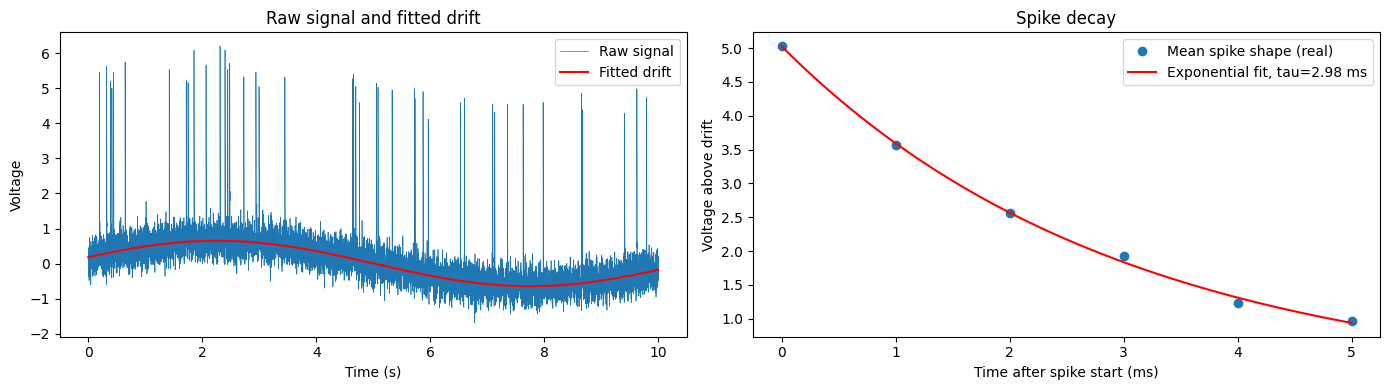

In [10]:
# 7. Visual check of the estimated model
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(t, raw_data, linewidth=0.5, label="Raw signal")
ax[0].plot(t, drift_fit, color="red", label="Fitted drift")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Voltage")
ax[0].set_title("Raw signal and fitted drift")
ax[0].legend()

lag_ms = np.arange(n_shape) / fs * 1000
fine_ms = np.linspace(0, lag_ms[-1], 100)
ax[1].plot(lag_ms, shape, "o", label="Mean spike shape (real)")
ax[1].plot(fine_ms, shape[0] * np.exp(-fine_ms / tau_ms), color="red", label=f"Exponential fit, tau={tau_ms:.2f} ms")
ax[1].set_xlabel("Time after spike start (ms)")
ax[1].set_ylabel("Voltage above drift")
ax[1].set_title("Spike decay")
ax[1].legend()

plt.tight_layout()
plt.show()

# 4. Simulate and save the results file

In [11]:
# 8. Simulator: drift + gaussian noise + exponentially decaying spikes
def simulate_signal(p, duration_s=10, fs=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = int(duration_s * fs)
    t_sim = np.arange(n) / fs
    x = (p["offset"] + p["amp"] * np.sin(2 * np.pi * p["freq"] * t_sim + p["phase"])
         + rng.normal(0, p["noise_sd"], n))

    # No spike can occur during the refractory time, so correct lambda to keep the same rate
    ref_s = p["ref_ms"] / 1000
    lam = 1 / (1 / p["rate"] - ref_s)
    ref_n = round(ref_s * fs)
    tau_samples = p["tau_ms"] / 1000 * fs
    u = rng.random(n)

    spikes, last = [], -10**9
    for i in range(n):
        if i - last >= ref_n and u[i] < lam / fs:      # refractory time passed and random draw succeeded
            spikes.append(i)
            last = i
            L = min(30, n - i)
            height = rng.normal(p["spike_amp"], p["spike_amp_sd"])
            x[i:i + L] += height * np.exp(-np.arange(L) / tau_samples)
    return t_sim, x, np.array(spikes)

In [12]:
# 9. Generate and save the results file (same structure as spike_data.npz)
t_sim, x_sim, sim_spike_idx = simulate_signal(params, duration_s=10, fs=round(fs), seed=0)
np.savez(out_dir + "/simulated_spike_data.npz", t=t_sim, raw_data=x_sim)

chk = np.load(out_dir + "/simulated_spike_data.npz")
assert chk.files == data.files
assert chk["t"].shape == t.shape and chk["raw_data"].shape == raw_data.shape
assert chk["t"].dtype == t.dtype and chk["raw_data"].dtype == raw_data.dtype
print("Arrays:", chk.files, "| first/last t:", chk["t"][0], chk["t"][-1])
print("Same structure as the original")

Arrays: ['t', 'raw_data'] | first/last t: 0.0 9.999
Same structure as the original


# 5. Testing module

In [13]:
%%writefile "/content/drive/MyDrive/Colab Notebooks/_utils/spike_tester.py"
import numpy as np

def spike_metrics(signal, threshold, fs=1000):
    """Summarise a signal with 6 numbers, using the same rising-edge rule and threshold."""
    above = signal > threshold
    edges = np.zeros(len(signal), dtype=bool)
    edges[0] = above[0]
    edges[1:] = above[1:] & ~above[:-1]
    idx = np.where(edges)[0]
    isi_ms = np.diff(idx) / fs * 1000
    return {
        "n_spikes": len(idx),
        "mean_spike_height": signal[idx].mean() if len(idx) else np.nan,
        "min_isi_ms": isi_ms.min() if len(isi_ms) else np.nan,
        "std": signal.std(),
        "min": signal.min(),
        "max": signal.max(),
    }

def closeness_score(real, sim, threshold, fs=1000):
    """Mean relative error over all metrics. 0 = identical, smaller = closer to the real data."""
    r = spike_metrics(real, threshold, fs)
    s = spike_metrics(sim, threshold, fs)
    return float(np.nanmean([abs(s[k] - r[k]) / abs(r[k]) for k in r]))

Writing /content/drive/MyDrive/Colab Notebooks/_utils/spike_tester.py


# 6. Compare and visualise

,real,sim_file,sim_2.5%,sim_97.5%,real_in_range
n_spikes,42.000,46.000,31.975,54.025,True
mean_spike_height,5.098,5.104,4.886,5.189,True
min_isi_ms,11.000,15.000,2.975,31.025,True
std,0.734,0.749,0.689,0.770,True
min,-1.691,-1.641,-1.853,-1.481,True
max,6.202,6.338,5.799,6.477,True


Closeness score of the file (0 = identical): 0.0884


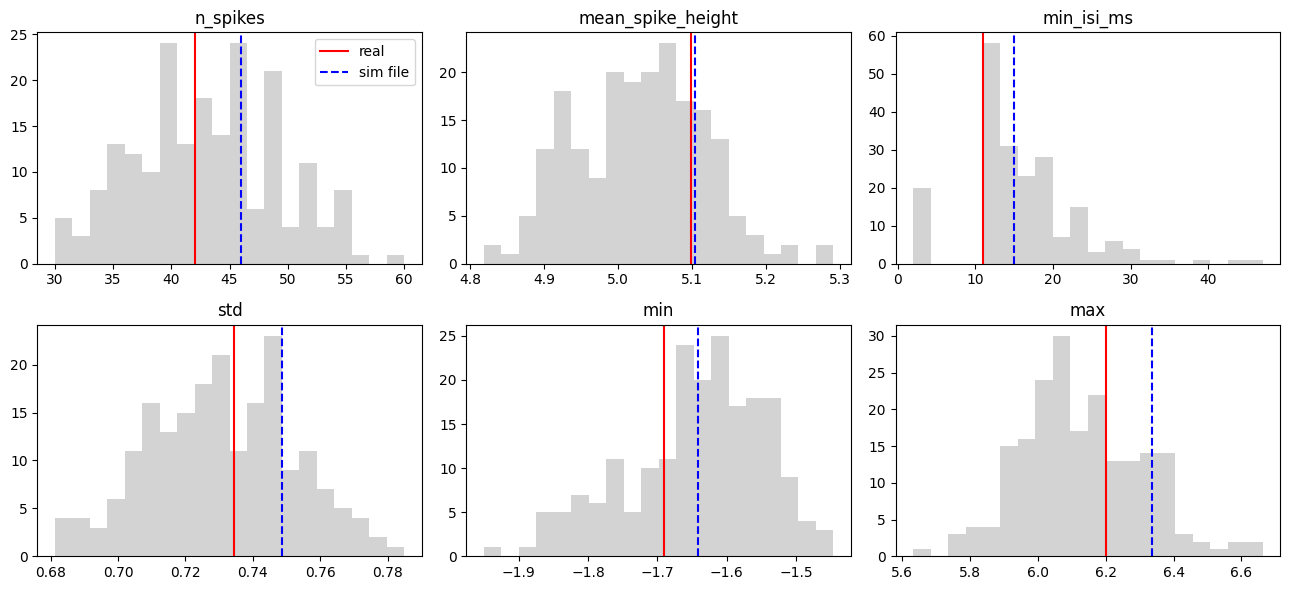

In [14]:
# 11. Use the testing module: real vs one simulated file vs 200 simulations
import importlib, spike_tester
importlib.reload(spike_tester)
from spike_tester import spike_metrics, closeness_score

real_m = spike_metrics(raw_data, thr_real, fs)
sim_m = spike_metrics(x_sim, thr_real, fs)

# Same model, 200 different seeds: shows how much the metrics vary by chance
many = pd.DataFrame([spike_metrics(simulate_signal(params, fs=round(fs), seed=s)[1], thr_real, fs)
                     for s in range(200)])

table = pd.DataFrame({"real": real_m, "sim_file": sim_m,
                      "sim_2.5%": many.quantile(0.025), "sim_97.5%": many.quantile(0.975)}).round(3)
table["real_in_range"] = (table["real"] >= table["sim_2.5%"]) & (table["real"] <= table["sim_97.5%"])
display(table)
print("Closeness score of the file (0 = identical):", round(closeness_score(raw_data, x_sim, thr_real, fs), 4))

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.ravel(), many.columns):
    ax.hist(many[name].dropna(), bins=20, color="lightgray")
    ax.axvline(real_m[name], color="red", label="real")
    ax.axvline(sim_m[name], color="blue", linestyle="--", label="sim file")
    ax.set_title(name)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

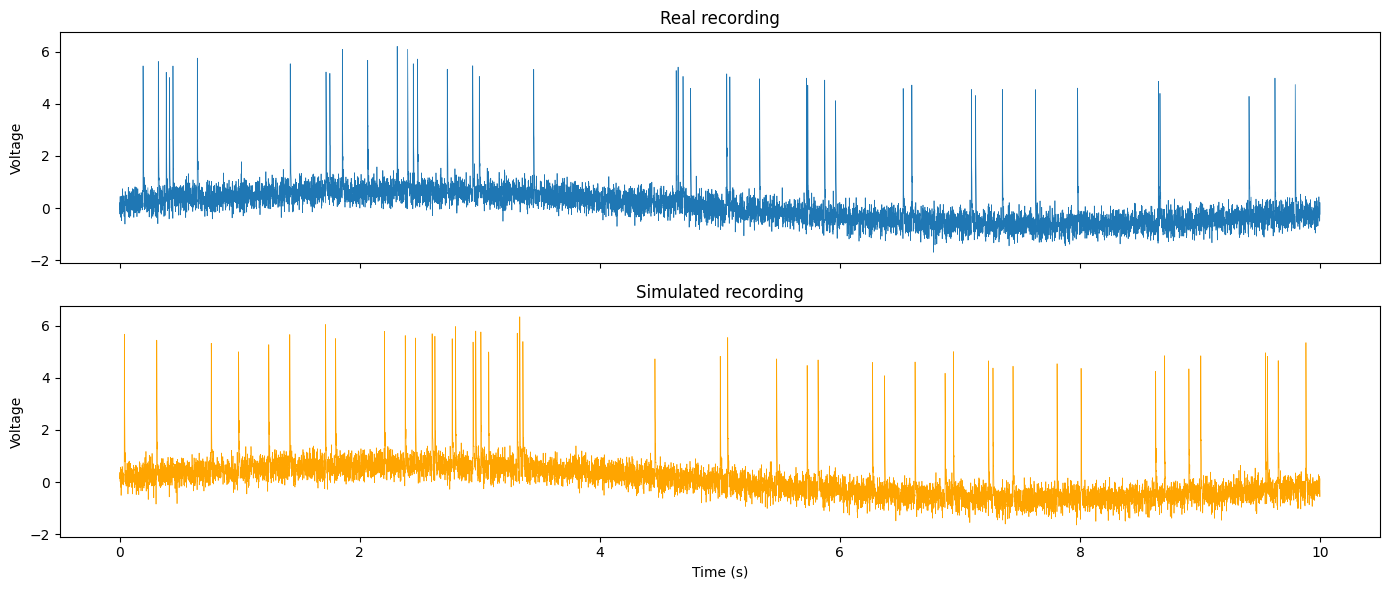

In [15]:
# 12. Real vs simulated signal
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
ax[0].plot(t, raw_data, linewidth=0.5)
ax[0].set_title("Real recording")
ax[1].plot(t_sim, x_sim, linewidth=0.5, color="orange")
ax[1].set_title("Simulated recording")
ax[1].set_xlabel("Time (s)")
for a_ in ax:
    a_.set_ylabel("Voltage")
plt.tight_layout()
plt.show()

# 7. Test

In [16]:
# 13. Tests for the simulation and the testing module
def run_simulation_tests():
    print("---Running Simulation & Testing-Module Tests---\n")

    # Test 1: identical signals -> score 0
    assert closeness_score(raw_data, raw_data, thr_real, fs) == 0
    print("Test 1 Passed: same signal -> score 0")

    # Test 2: known small signal -> known metrics
    m = spike_metrics(np.array([1.0, 3.0, 3.0, 1.0, 3.0]), 2.0, fs=1000)
    assert m["n_spikes"] == 2 and m["mean_spike_height"] == 3.0 and m["min_isi_ms"] == 3.0
    print("Test 2 Passed: known signal -> 2 events, height 3.0, min ISI 3 ms")

    # Test 3: results file has the same structure as the original
    assert chk.files == data.files and chk["raw_data"].shape == raw_data.shape
    print("Test 3 Passed: results file has the same structure")

    # Test 4: simulation is closer to the real data than noise only (no spikes)
    noise_only = np.random.default_rng(1).normal(0, noise_sd, len(raw_data))
    assert closeness_score(raw_data, x_sim, thr_real, fs) < closeness_score(raw_data, noise_only, thr_real, fs)
    print("Test 4 Passed: simulation is closer than noise only")

    print("\nDone!")

run_simulation_tests()

---Running Simulation & Testing-Module Tests---

Test 1 Passed: same signal -> score 0
Test 2 Passed: known signal -> 2 events, height 3.0, min ISI 3 ms
Test 3 Passed: results file has the same structure
Test 4 Passed: simulation is closer than noise only

Done!
